# 02 — Rotation Forest: training, evaluation and explainability

Training is run by `python -m src.train` and explanations by `python -m src.explain` (`dvc repro` runs both).
This notebook loads their saved outputs, so it runs in seconds and every number here is reproducible.

**Evaluation protocol**
* Grouped splits: all days of a household are on the same side of every split (days of one home are near-duplicates).
* 20% of households are held out as the test set and scored once, at the end.
* The grid search and the decision threshold use training households only.
* Every model trains on the same sample of at most 40 days per training household; the test set keeps every day.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.precision", 4)
R = "../reports"
comp = pd.read_csv(f"{R}/model_comparison.csv")
meta = json.load(open("../models/metadata.json"))
best = json.load(open(f"{R}/best_params.json"))

## 1. The algorithm: Rotation Forest

**Rotation Forest** (Rodríguez, Kuncheva & Alonso, *IEEE TPAMI* 2006) is a tree ensemble that was not covered in
the lectures. For every tree it

1. splits the 64 features at random into small disjoint subsets (K features each),
2. fits PCA on each subset, using a random sub-sample of rows, and keeps *all* components,
3. places these rotations in one block matrix R and trains a decision tree on X·R,

and the forest averages the trees' probabilities.

**How it differs from the standard models.** A decision tree, random forest or gradient-boosting model only splits
on the original axes ("h12_share < 0.02"). The solar signature is a *relation* between features (midday import low
compared with night and evening import), so axis-aligned trees approximate it with a staircase of splits. Each
rotated tree splits on linear combinations of features instead, and because every tree gets a different rotation,
the trees stay accurate *and* diverse, which is what makes an ensemble work. Unlike bagging/random forest, diversity
comes from the rotation, not from throwing data away: keeping all principal components loses no information.

**Why it was chosen.** Tabular, engineered, correlated features (hourly kWh and hourly shares move together), a
non-linear but smooth boundary, and the need for a model that is explainable with SHAP/LIME/PDP. Deep learning is
not allowed, and boosting/stacking were covered in the lectures. Implementation: `src/rotation_forest.py`
(scikit-learn compatible, unit-tested in `tests/test_rotation_forest.py`).

## 2. Hyperparameter search (grid, grouped 3-fold CV on 50% of training households, log loss)

In [2]:
grid = pd.read_csv(f"{R}/rotation_forest_grid_search.csv")
print("chosen:", best["rotation_forest"])
grid

chosen: {'subset_size': 3, 'max_features': None, 'min_samples_leaf': 20, 'n_estimators': 100, 'sample_fraction': 0.75}


,subset_size,max_features,min_samples_leaf,cv_logloss,cv_logloss_std,cv_day_auc,seconds
0,3,NaN,20,0.0960,0.0093,0.9857,61.5
1,6,NaN,20,0.1005,0.0085,0.9849,95.2
2,3,sqrt,20,0.1045,0.0120,0.9835,8.8
3,3,NaN,5,0.1060,0.0207,0.9833,73.6
4,6,sqrt,20,0.1072,0.0072,0.9839,11.9
5,3,sqrt,5,0.1087,0.0161,0.9830,9.5
6,6,NaN,5,0.1095,0.0184,0.9829,69.3
7,6,sqrt,5,0.1108,0.0122,0.9828,13.5


Log loss on days is used as the objective because it is smooth; household accuracy changes by whole
households and is too coarse to rank settings. The number of trees is not tuned: more trees never hurt a forest,
they only cost time. The curve below shows where adding trees stops helping.

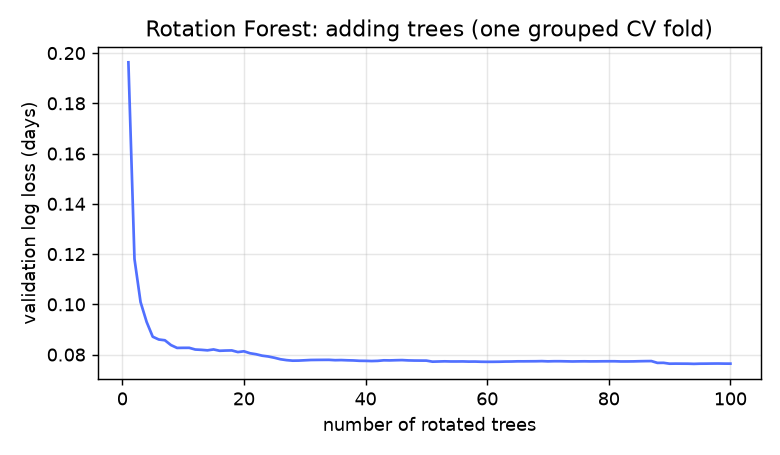

,trees,logloss,auc
0,1,0.1963,0.9658
4,5,0.0871,0.9882
9,10,0.0827,0.9890
24,25,0.0787,0.9895
49,50,0.0776,0.9897
99,100,0.0764,0.9898


In [3]:
display(Image(f"{R}/figures/trees_curve.png"))
pd.read_csv(f"{R}/trees_curve.csv").iloc[[0, 4, 9, 24, 49, -1]]

## 3. Rotation Forest against the lecture algorithms

In [4]:
cols = ["model", "stage", "cv_hh_accuracy", "cv_hh_auc", "cv_day_logloss", "test_hh_accuracy", "test_hh_auc",
        "test_hh_errors", "test_hh_f1", "seconds"]
comp[cols].sort_values("cv_day_logloss")

,model,stage,cv_hh_accuracy,cv_hh_auc,cv_day_logloss,test_hh_accuracy,test_hh_auc,test_hh_errors,test_hh_f1,seconds
10,"Soft voting (ET, XGB, LGBM, CatBoost)",baseline,0.9903,0.9986,0.0657,0.9901,0.9985,6,0.9700,0.0
9,CatBoost,baseline,0.9903,0.9985,0.0670,0.9918,0.9982,5,0.9751,30.1
7,XGBoost,baseline,0.9912,0.9981,0.0691,0.9901,0.9982,6,0.9703,21.3
6,HistGradientBoosting,baseline,0.9891,0.9982,0.0692,0.9901,0.9979,6,0.9700,8.9
8,LightGBM,baseline,0.9895,0.9981,0.0693,0.9901,0.9982,6,0.9700,23.4
13,Rotation Forest,main,0.9870,0.9987,0.0735,0.9885,0.9985,7,0.9648,1468.9
4,Random Forest,baseline,0.9861,0.9987,0.0739,0.9885,0.9990,7,0.9648,84.2
11,"Stacking (ET, XGB, LGBM, CatBoost -> LR)",baseline,0.9886,0.9979,0.0756,0.9901,0.9969,6,0.9700,0.2
5,Extra Trees,baseline,0.9857,0.9983,0.0791,0.9885,0.9988,7,0.9648,14.1
3,Decision Tree,baseline,0.9874,0.9966,0.1361,0.9901,0.9982,6,0.9700,16.3


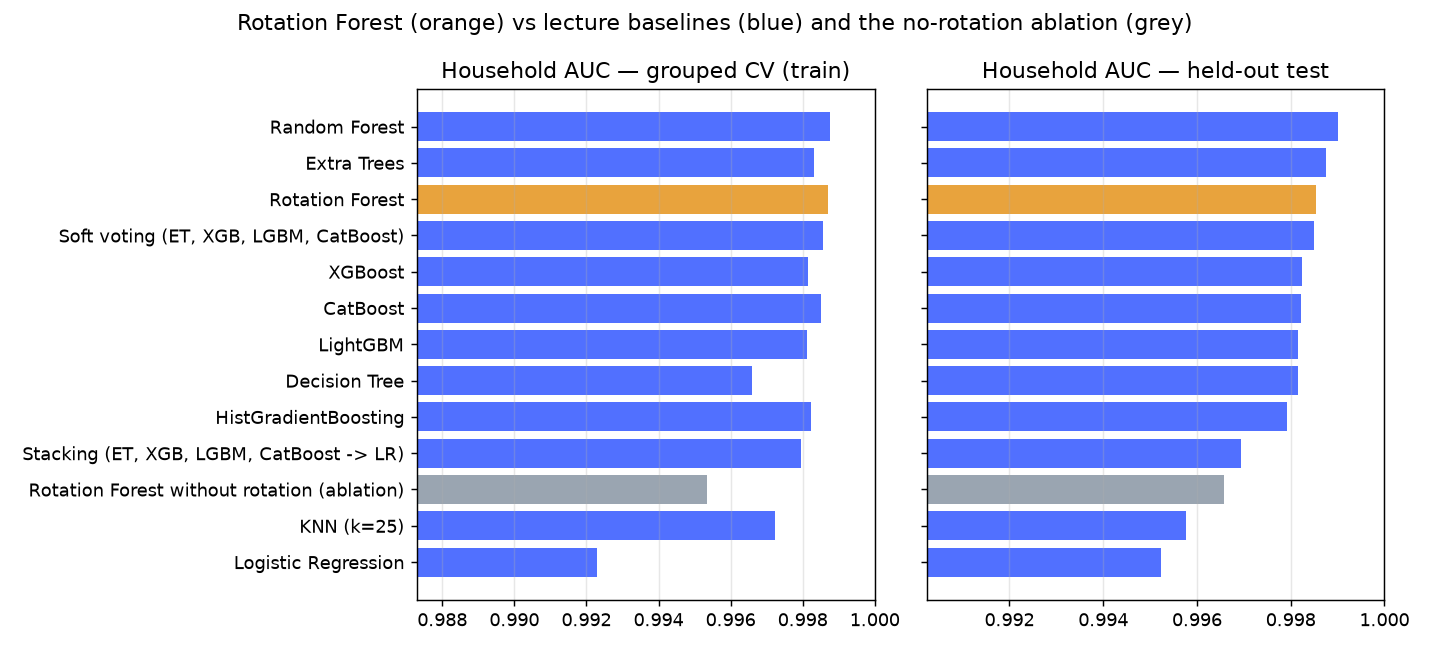

In [5]:
display(Image(f"{R}/figures/model_comparison.png"))

* **Rotation vs. no rotation (ablation).** The same forest with the rotation switched off is clearly worse,
  so the gain comes from the rotation itself, not just from averaging many trees.
* Grouped CV on 2,300+ training households is the more reliable comparison; the test set has only 608
  household-periods, so a difference of one or two errors there is within noise.
* The household decision averages the day probabilities and compares the mean with a threshold chosen on the
  training households (out-of-fold).

## 4. Final result on the held-out test households

In [6]:
print(meta["model"], "| threshold", meta["threshold"])
pd.DataFrame({"CV (train households)": meta["cv_train_households"], "Test (held out)": meta["test_households"]})

Rotation Forest (100 PCA-rotated decision trees) | threshold 0.46


,CV (train households),Test (held out)
hh_accuracy,0.9895,0.9885
hh_f1,0.9670,0.9648
hh_precision,0.9892,1.0000
hh_recall,0.9457,0.9320
hh_auc,0.9987,0.9985
hh_errors,25.0000,7.0000
hh_n,2377.0000,608.0000
day_accuracy,0.9758,0.9820
day_auc,0.9913,0.9934
day_logloss,0.0735,0.0602


## 5. Error analysis

In [7]:
hh = pd.read_csv(f"{R}/test_household_predictions.csv")
errors = hh[hh.pred != hh.solar_installed].sort_values("p_solar")
errors

,unit,hh,solar_installed,p_solar,n_days,export_kwh,first_export_day,pred
379,ID4448:1,ID4448,1,0.0598,3,21.4040,2024-05-31,0
582,ID5472:1,ID5472,1,0.1297,88,93.0750,2024-06-26,0
8,ID0183:1,ID0183,1,0.2108,182,3072.5247,2024-04-13,0
31,ID0485:1,ID0485,1,0.2865,21,463.2949,2023-12-13,0
600,ID5543:1,ID5543,1,0.3529,25,482.2727,2024-09-15,0
530,ID5246:1,ID5246,1,0.4491,108,323.1992,2023-11-07,0
465,ID4896:1,ID4896,1,0.4559,255,31671.2340,2023-10-01,0


In [8]:
hh["days"] = pd.cut(hh.n_days, [0, 7, 30, 10_000], labels=["1-7", "8-30", ">30"])
hh.groupby("days", observed=True).apply(lambda d: pd.Series({"households": len(d),
    "accuracy": (d.pred == d.solar_installed).mean()}))

/var/folders/ms/yxpz1w791gx3pr3c0z7rcfh80000gn/T/ipykernel_70919/1560565809.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  hh.groupby("days", observed=True).apply(lambda d: pd.Series({"households": len(d),


,households,accuracy
days,,
1-7,11.0,0.9091
8-30,15.0,0.8667
>30,582.0,0.9931


The model and threshold were frozen before this analysis. Errors concentrate in households with few days of
data, very small exporters and homes whose import barely changes (likely battery/hybrid systems): one day can be
ambiguous (cloudy weather, an empty house), and averaging over weeks removes most of that noise.

## 6. Explainability — SHAP (permutation, whole forest)

The trees split on rotated axes, so tree-SHAP would explain mixtures of features. Permutation SHAP explains the
whole forest in terms of the original, readable features; values are changes in P(solar).

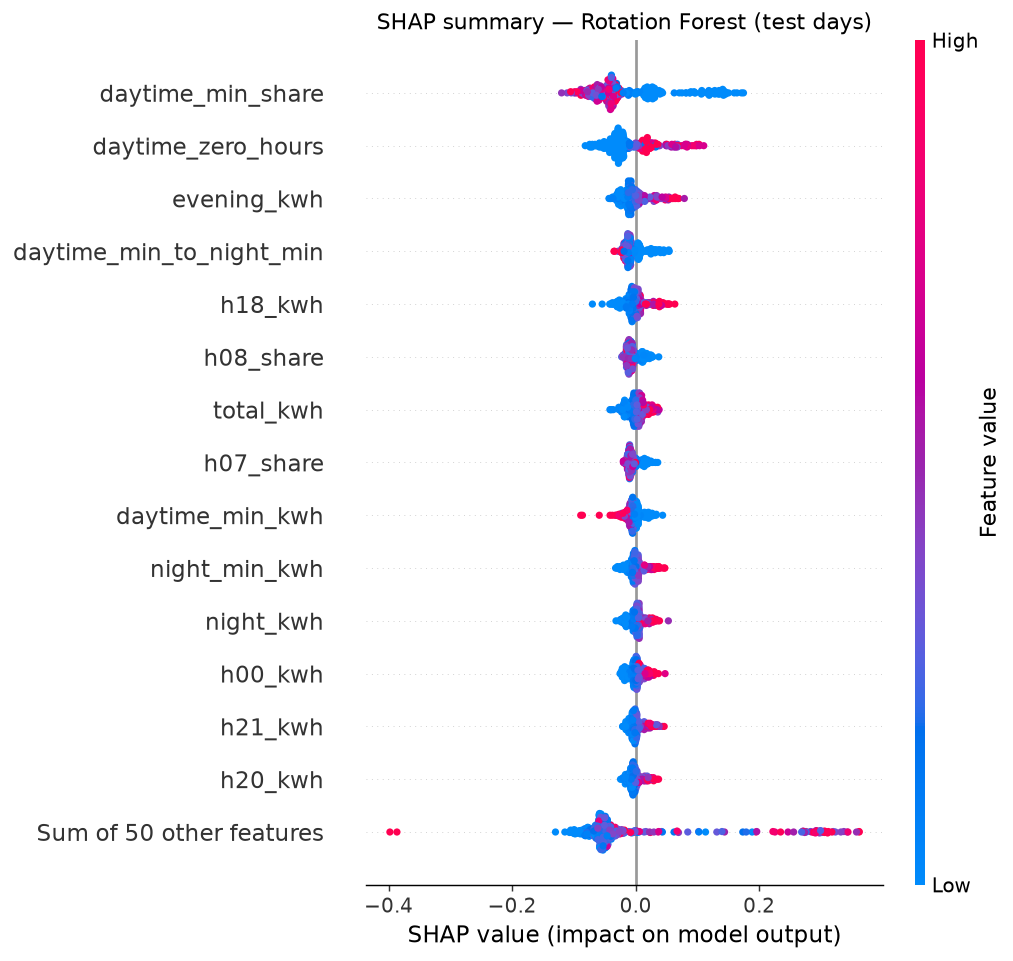

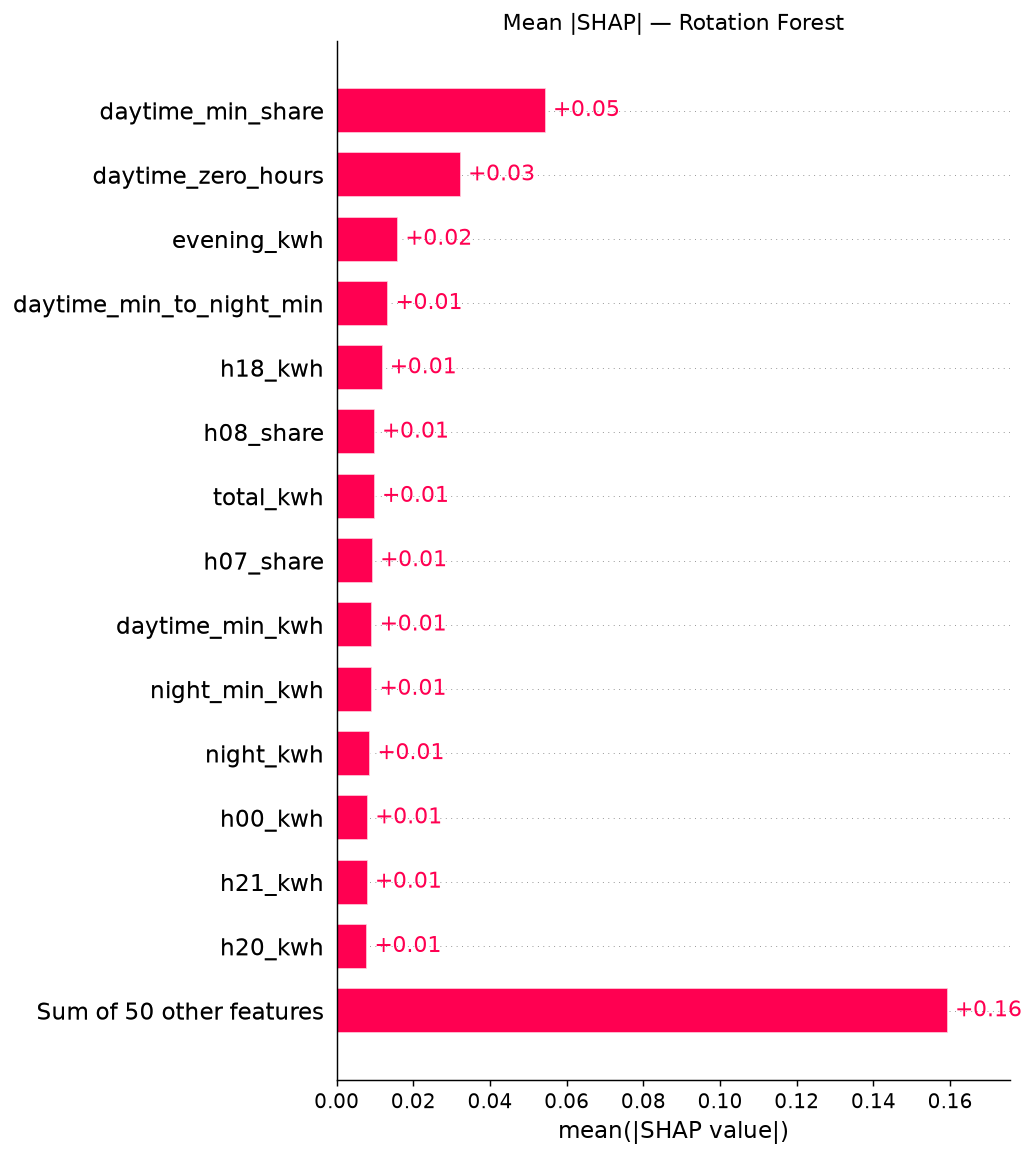

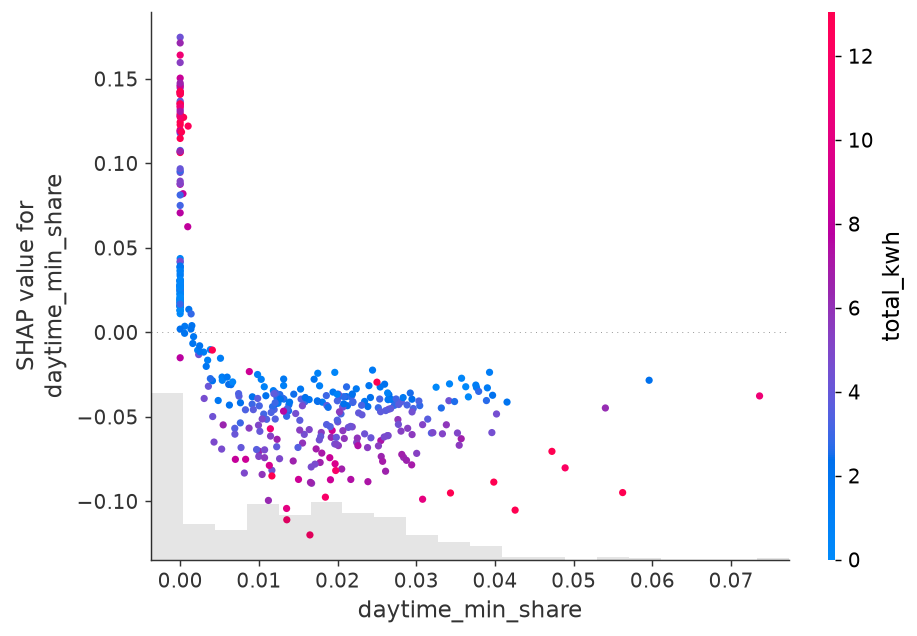

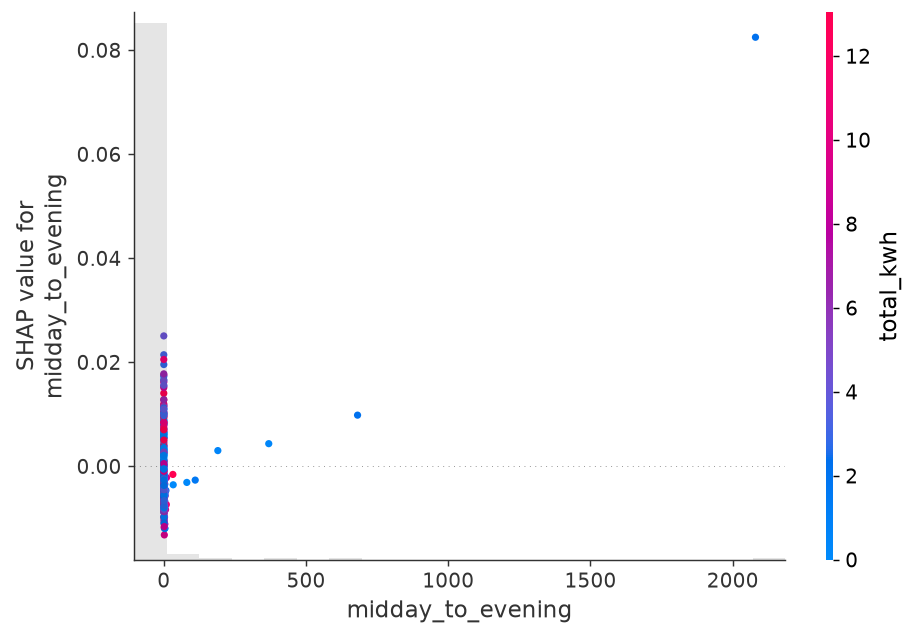

,mean_abs_shap
daytime_min_share,0.0545
daytime_zero_hours,0.0324
evening_kwh,0.0160
daytime_min_to_night_min,0.0135
h18_kwh,0.0120
h08_share,0.0099
total_kwh,0.0099
h07_share,0.0095
daytime_min_kwh,0.0093
night_min_kwh,0.0093


In [9]:
for f in ["shap_beeswarm", "shap_bar", "shap_dependence_daytime_min_share", "shap_dependence_midday_to_evening"]:
    display(Image(f"{R}/explain/{f}.png"))
pd.read_csv(f"{R}/explain/shap_importance.csv", index_col=0).head(10)

The leading features describe **how low daytime import gets relative to the rest of the day**: on a sunny
day the panels cover the home's load, so the meter imports almost nothing between 09:00 and 15:00 and imports
normally in the evening. This is the physical mechanism of rooftop solar, so the model's behaviour matches domain
knowledge; it does not rely on calendar or meter artefacts (calendar month was removed for that reason, see README).

## 7. Partial dependence (PDP + ICE)

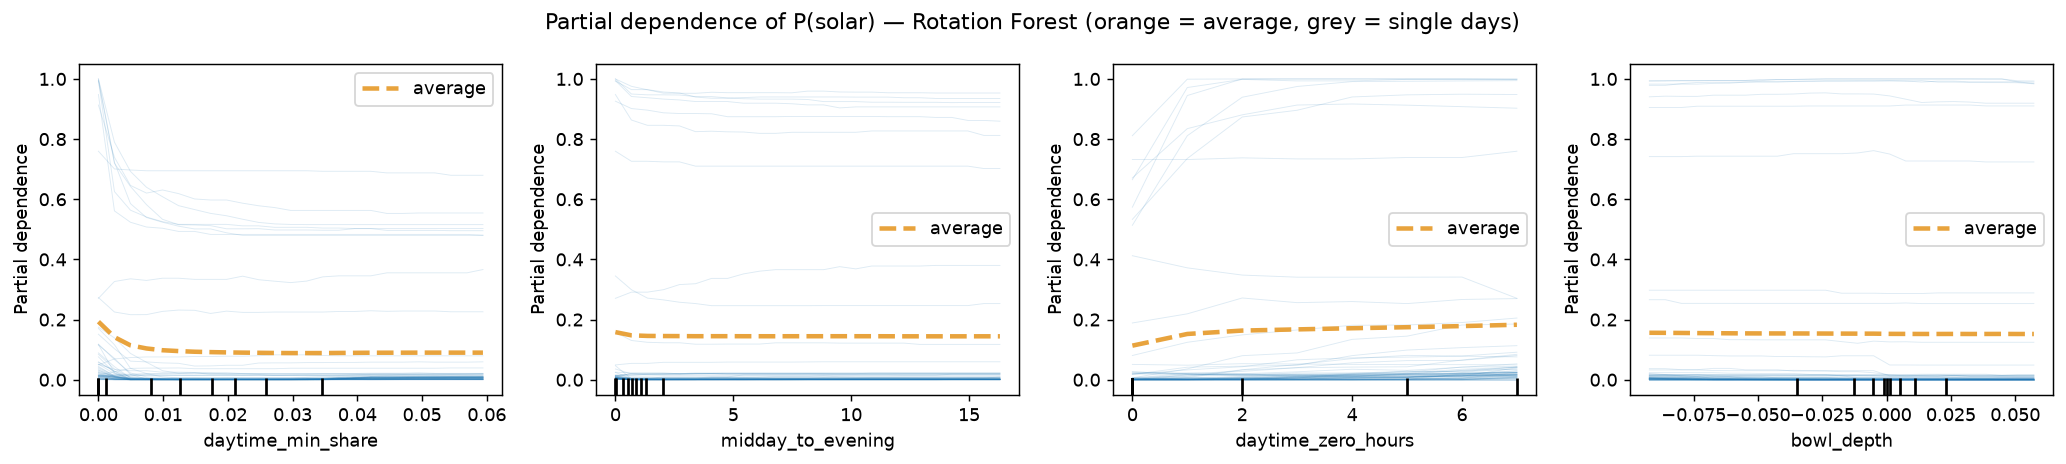

In [10]:
display(Image(f"{R}/explain/pdp.png"))

## 8. Local explanations — SHAP waterfalls and LIME

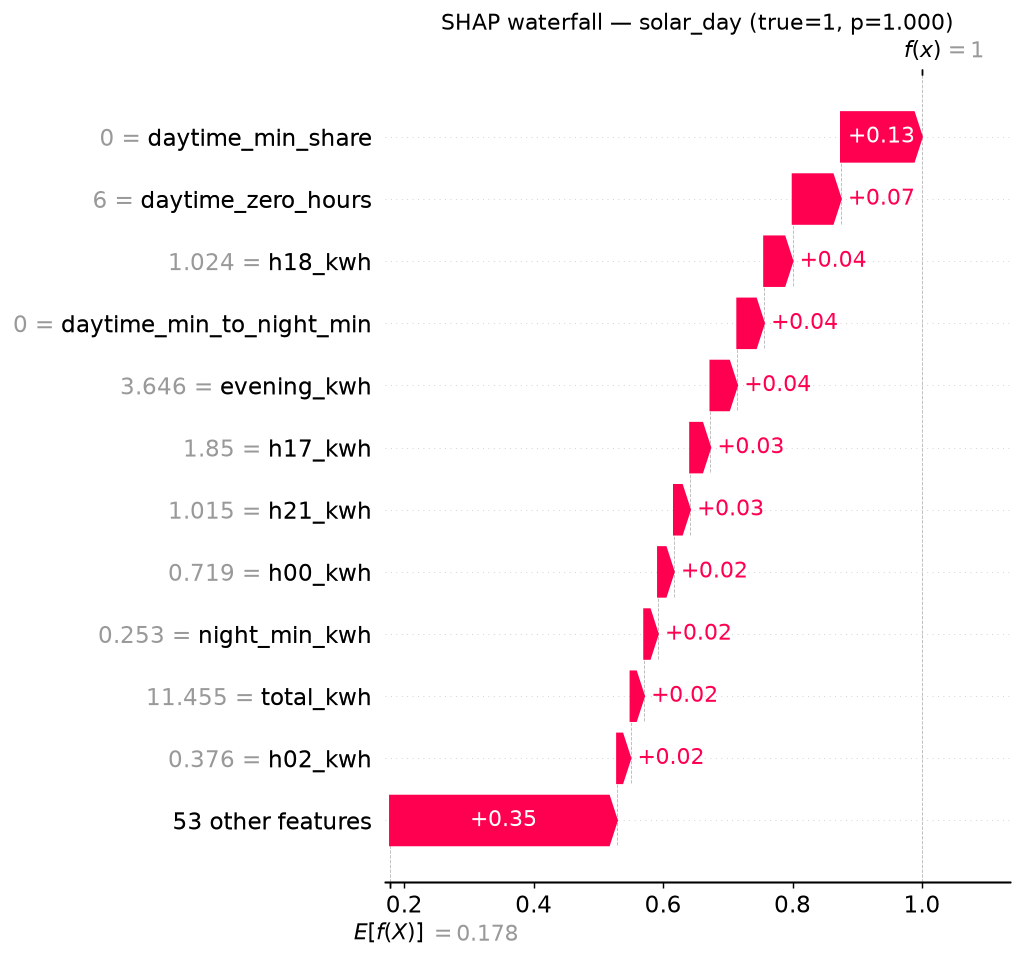

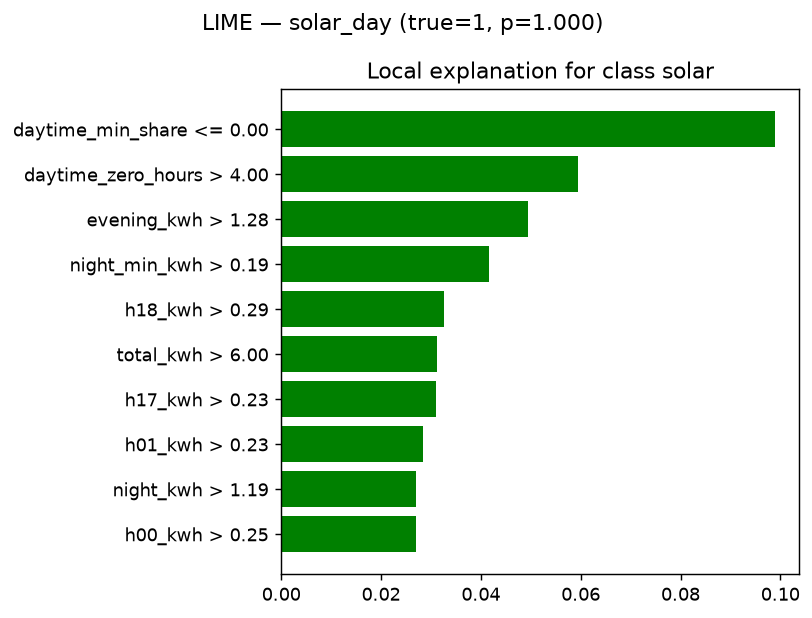

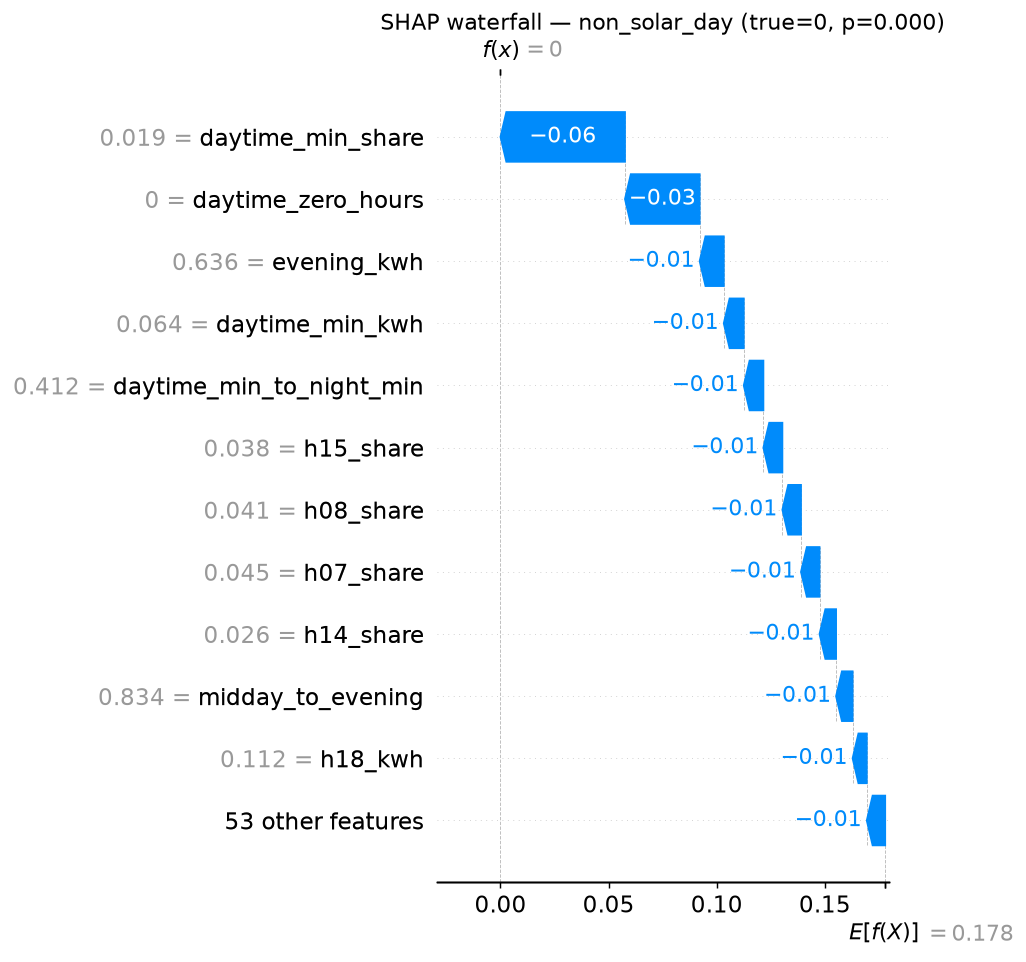

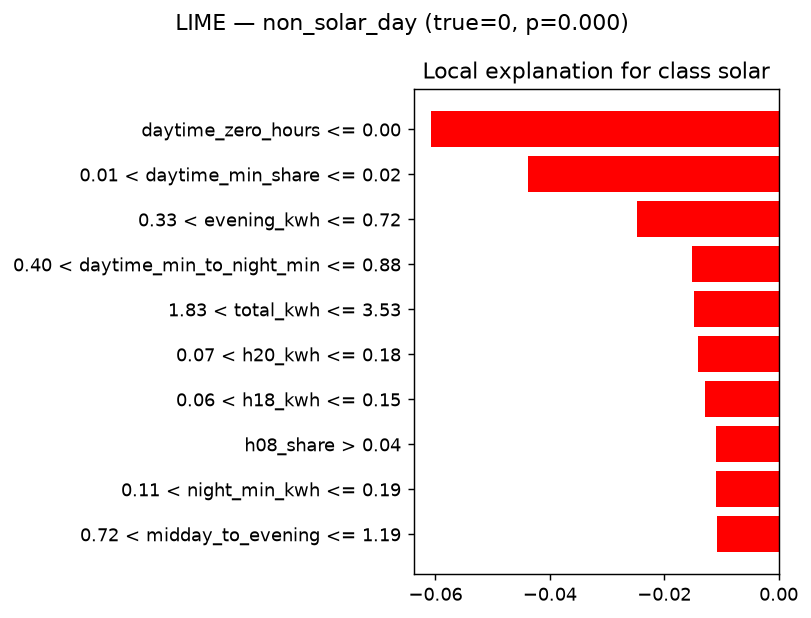

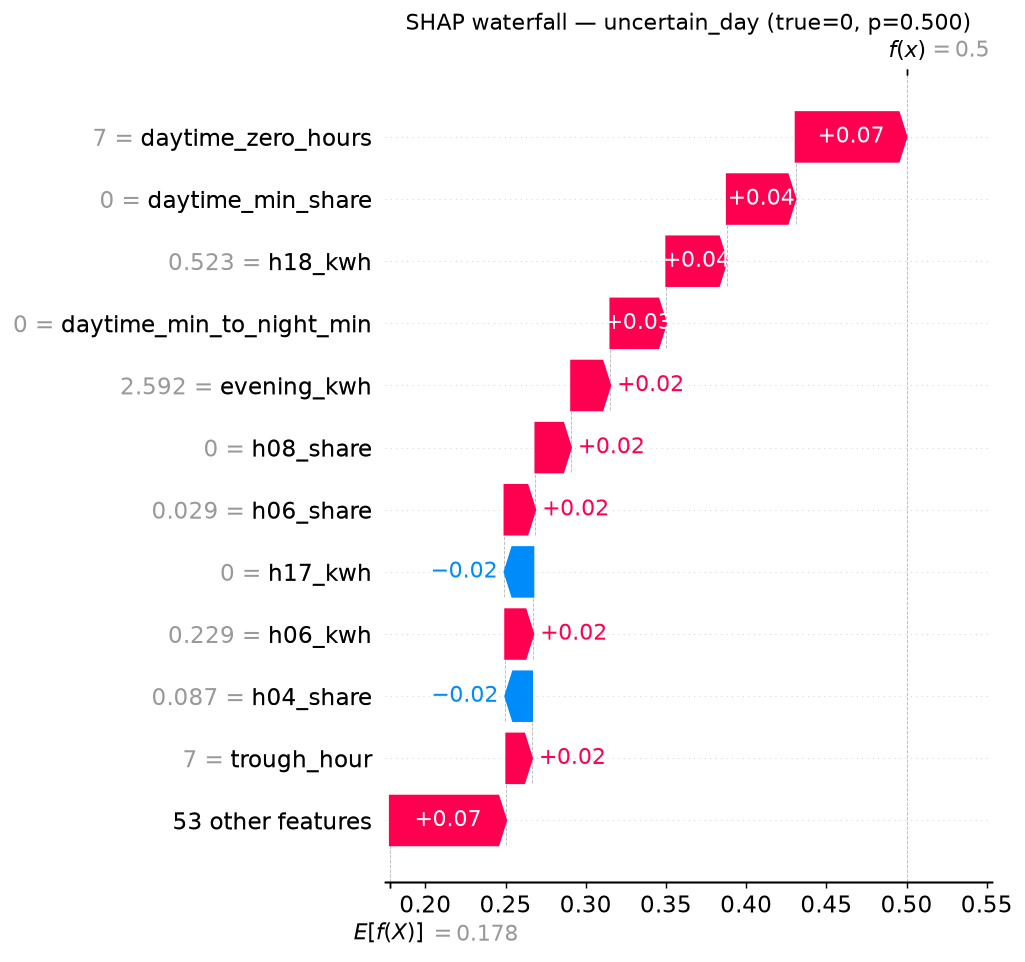

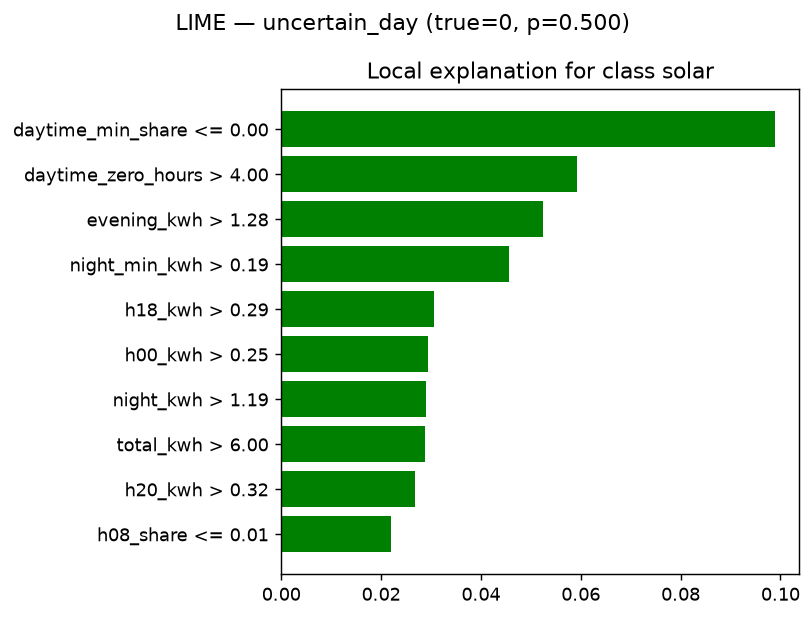

,case,hh,day,true,p_solar,rule,weight
0,solar_day,ID0264,2023-12-18,1,1.0,daytime_min_share <= 0.00,0.0989
1,solar_day,ID0264,2023-12-18,1,1.0,daytime_zero_hours > 4.00,0.0596
2,solar_day,ID0264,2023-12-18,1,1.0,evening_kwh > 1.28,0.0495
3,solar_day,ID0264,2023-12-18,1,1.0,night_min_kwh > 0.19,0.0417
4,solar_day,ID0264,2023-12-18,1,1.0,h18_kwh > 0.29,0.0327
5,solar_day,ID0264,2023-12-18,1,1.0,total_kwh > 6.00,0.0312
6,solar_day,ID0264,2023-12-18,1,1.0,h17_kwh > 0.23,0.0310
7,solar_day,ID0264,2023-12-18,1,1.0,h01_kwh > 0.23,0.0284
8,solar_day,ID0264,2023-12-18,1,1.0,night_kwh > 1.19,0.0270
9,solar_day,ID0264,2023-12-18,1,1.0,h00_kwh > 0.25,0.0269


In [11]:
for case in ["solar_day", "non_solar_day", "uncertain_day"]:
    display(Image(f"{R}/explain/shap_waterfall_{case}.png"))
    display(Image(f"{R}/explain/lime_{case}.png"))
pd.read_csv(f"{R}/explain/lime_explanations.csv")

SHAP and LIME agree on the confident cases. The most uncertain day (P = 0.50) comes from a home *without*
solar whose import was near zero for several daytime hours (nobody home, or a supply interruption), which looks
exactly like a sunny solar day. A single day cannot tell these apart, which is why the household verdict averages
many days.